# 数据预处理

In [44]:
 # 这是 denoising_test.ipynb 的第 2 个单元格，属于历史学习实验。
# Notebook 与 .py 不同：多个单元格共享内核变量，通常要按顺序运行前置单元格。
# 本次只增加注释，保留原实验行为和已有输出；正式项目的修正请以各包内 .py 为准。

# 导入 torch，使用张量、神经网络计算及自动求导
import torch  # 导入PyTorch库，用于深度学习任务
# 从 PIL 导入 Image，用于通过 Pillow 打开、转换和生成图片。
from PIL import Image  # 导入PIL库中的Image模块，用于图像处理
# 导入 os，读取环境变量或进行旧实验中的目录操作
import os  # 导入os库，用于处理文件和目录路径

from requests.packages import target
# 从 torch.utils.data 导入 Dataset，用于使用张量、神经网络计算及自动求导。
from torch.utils.data import Dataset,DataLoader,random_split  # 从PyTorch的工具库中导入Dataset类，用于自定义数据集

# =======ImageDataset：每次返回一张带噪图及其对应的原图===========================================
# 定义 ImageDataset 数据集类并继承父类能力；只重写与当前任务不同的部分。
class ImageDataset(Dataset):  # 定义一个名为ImageDataset的类，继承自PyTorch的Dataset类
    # 创建对象时自动执行的初始化方法；self 表示正在创建的这个对象。
    # self.xxx 把数据保存在对象中，让这个对象的其他方法以后也能使用。
    def __init__(self, main_dir, transform=None):  # 定义类的构造函数，接受两个参数：main_dir（主目录路径）和transform（图像预处理操作，默认为None）
        # 将这项初始化结果保存在 self.main_dir 中，供同一对象或测试类的后续方法使用。
        self.main_dir = main_dir  # 将主目录路径保存为类的属性
        # 将这项初始化结果保存在 self.transform 中，供同一对象或测试类的后续方法使用。
        self.transform = transform  # 将图像预处理操作保存为类的属性
        # 将这项初始化结果保存在 self.all_imgs 中，供同一对象或测试类的后续方法使用。
        self.all_imgs = os.listdir(main_dir)  # 获取主目录下的所有文件名，并保存为列表

    # Python 执行 len(数据集对象) 时自动调用这个方法，得到图片数量。
    def __len__(self):  # 定义__len__方法，返回数据集中图像的数量
        # 把 len(self.all_imgs) 交还给调用方，并结束本次函数调用；return 不会打印结果。
        return len(self.all_imgs)  # 返回主目录下图像文件的数量

    # 根据索引号得到（input,target）
    # Python 执行 dataset[idx] 时自动调用这个方法；DataLoader 也通过它逐个取样本。
    def __getitem__(self, idx):  # 定义__getitem__方法，根据索引idx获取图像
        # 1.把目录和当前文件名拼成图片路径；idx 是列表下标，不是文件名中的图片 id。
        img_loc = os.path.join(self.main_dir, self.all_imgs[idx])  # 根据索引idx构建图像的完整路径
        # 从路径打开图片并按需要转换颜色模式；读取的是图片内容，不是文件名字符串。
        image = Image.open(img_loc).convert("RGB")  # 使用PIL库打开图像并将其转换为RGB格式

        # 2.将原始图片转换为符合模型输入要求的张量，这就是重构图像的目标
        # 条件分支：只有 self.transform is not None 为真时才执行下方缩进代码；否则跳过或进入对应 else 分支。
        if self.transform is not None:  # 如果定义了图像预处理操作
            # 调用预处理，把 PIL 图片变为模型可以运算的 [3,H,W] 张量。
            tensor_image = self.transform(image)  # 对图像进行预处理，并将其转换为张量
        # else：前面的对应条件不成立（或 try 无异常）时，执行这个分支。
        else:
            # 若无变换，抛出异常提示必须提供预处理
            # 主动抛出有说明的异常，停止当前错误路径；上层命令行或 Flask 错误处理器决定如何向用户展示。
            raise ValueError("transform参数不能为None，需指定预处理方法")

        # 3.添加随机噪声
        # 为 noise_factor 设置初始值；后续语句可以读取或更新这个名字指向的值。
        noise_factor = 0.5
        ## 向输入图像添加随机噪声
        # 生成与 tensor_image 形状相同的随机噪声，乘以噪声因子 noise_factor
        # 从标准正态分布采样随机数；负数也会出现，可用来构造噪声或测试张量。
        noisy_imgs = tensor_image + noise_factor * torch.randn_like(tensor_image)
        # 将图像像素值裁剪到 [0, 1] 范围内，避免超出有效范围
        # 将加噪后的像素裁回 [0,1]，小于 0 的值取 0，大于 1 的值取 1。
        noisy_imgs = torch.clip(noisy_imgs, 0., 1.)

        # 4.将输入和输出返回
        # 把多个结果打包为元组返回；调用处可以用 a,b=函数(...) 按顺序接住。
        return noisy_imgs, tensor_image  # 返回预处理后的图像张量（将噪声图片作为输入，将原图作为目标）


In [52]:
import torchvision.transforms as transforms #用于图像预处理
transform = transforms.Compose([
    transforms.Resize((64, 64)),  # 调整图像大小为 256x256
    transforms.ToTensor(),  # 将图像转换为 PyTorch 张量
])


In [53]:
dataset = ImageDataset(main_dir = 'common/dataset',transform=transform)
print(len(dataset))

24853


# 划分数据集

In [54]:
train_dataset,test_dataset = random_split(dataset,[0.75,0.25])
print(len(train_dataset))
print(len(test_dataset))

18640
6213


# 构建数据加载器

In [56]:
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, drop_last=True)

In [57]:
data_iter = iter(train_loader)  #取出一批数据

In [58]:
input,target = next(data_iter)
print(input.shape)
print(target.shape)

torch.Size([32, 3, 64, 64])
torch.Size([32, 3, 64, 64])


# 2.定义模型（前向传播验证）

In [29]:

# 这是 denoising_test.ipynb 的第 4 个单元格，属于历史学习实验。
# Notebook 与 .py 不同：多个单元格共享内核变量，通常要按顺序运行前置单元格。
# 本次只增加注释，保留原实验行为和已有输出；正式项目的修正请以各包内 .py 为准。

# 导入 torch，使用张量、神经网络计算及自动求导
import torch
# 导入 torch.nn，使用张量、神经网络计算及自动求导；as nn 给它起较短别名
import torch.nn as nn
# 导入 torch.nn.functional，使用张量、神经网络计算及自动求导；as F 给它起较短别名
import torch.nn.functional as F

# 定义神经网络架构
# 定义 ConvDenoiser 网络类，继承 nn.Module 以便 PyTorch 自动登记子层、参数及训练模式。
class ConvDenoiser(nn.Module):
    # 创建对象时自动执行的初始化方法；self 表示正在创建的这个对象。
    # self.xxx 把数据保存在对象中，让这个对象的其他方法以后也能使用。
    def __init__(self): # 创建该类的实例的时候会自动调用初始化方法__init__
        # 先调用父类 nn.Module 初始化，之后 PyTorch 才能正确登记卷积层和参数。
        super(ConvDenoiser, self).__init__()
        ## 编码器层 ##
        # 卷积层 (输入通道数从1变为32), 3x3卷积核
        # 建立二维卷积层：输入通道 3、输出通道 32、卷积核 3；本项目常用 padding=1 保持高宽。
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1)
        # 卷积层 (输入通道数从32变为16), 3x3卷积核
        # 建立二维卷积层：输入通道 32、输出通道 16、卷积核 3；本项目常用 padding=1 保持高宽。
        self.conv2 = nn.Conv2d(32, 16, 3, padding=1)
        # 卷积层 (输入通道数从16变为8), 3x3卷积核
        # 建立二维卷积层：输入通道 16、输出通道 8、卷积核 3；本项目常用 padding=1 保持高宽。
        self.conv3 = nn.Conv2d(16, 8, 3, padding=1)
        # 池化层，用于将x-y维度减少一半；卷积核和步幅均为2
        # 建立最大池化层：每个小窗口取最大值；这里通常用 2×2 窗口把高和宽各减半，不改变通道数。
        self.pool = nn.MaxPool2d(2, 2)

        ## 解码器层 ##
        # 转置卷积层，卷积核为2，步幅为2，将空间维度增加2倍
        # 建立转置卷积层：通道 8→8；它通过可训练参数上采样，不是把编码运算精确倒过来。
        self.t_conv1 = nn.ConvTranspose2d(8, 8, 2, stride=2)
        # 建立转置卷积层：通道 8→16；它通过可训练参数上采样，不是把编码运算精确倒过来。
        self.t_conv2 = nn.ConvTranspose2d(8, 16, 2, stride=2)
        # 建立转置卷积层：通道 16→32；它通过可训练参数上采样，不是把编码运算精确倒过来。
        self.t_conv3 = nn.ConvTranspose2d(16, 32, 2, stride=2)
        # 最后一个普通的卷积层，用于减少通道数
        # 建立二维卷积层：输入通道 32、输出通道 3、卷积核 3；本项目常用 padding=1 保持高宽。
        self.conv_out = nn.Conv2d(32, 3, 3, padding=1)

    # forward函数用于向前传播，该函数接受一个输入张量x，并返回一个输出张量，该函数的实现真正决定了神经网络的架构
    # 定义模型前向计算；外部写 model(x) 时，PyTorch 的调用机制会执行这里的运算。
    # x 是张量，后面的 x = ... 表示把中间结果继续传给下一层，不是反向传播。
    def forward(self, x):
        ## 编码 ##
        # 添加带有ReLU激活函数的隐藏层
        # 并在之后进行最大池化
        # 先执行卷积提取局部特征，再用 ReLU 引入非线性；此处尚未进行池化。
        x = F.relu(self.conv1(x))
        # print("conv1 shape: ", x.shape)
        # 最大池化只压缩空间尺寸：高宽约减半，批次大小和通道数保持不变。
        x = self.pool(x)
        # print("pool1 shape: ", x.shape)
        # 添加第二个隐藏层
        # 先执行卷积提取局部特征，再用 ReLU 引入非线性；此处尚未进行池化。
        x = F.relu(self.conv2(x))
        # print("conv2 shape: ", x.shape)
        # 最大池化只压缩空间尺寸：高宽约减半，批次大小和通道数保持不变。
        x = self.pool(x)
        # print("pool2 shape: ", x.shape)
        # 添加第三个隐藏层
        # 先执行卷积提取局部特征，再用 ReLU 引入非线性；此处尚未进行池化。
        x = F.relu(self.conv3(x))
        # print("conv3 shape: ", x.shape)
        # 最大池化只压缩空间尺寸：高宽约减半，批次大小和通道数保持不变。
        x = self.pool(x)  # 压缩表示
        # print("pool3 shape: ", x.shape)

        ## 解码 ##
        # 添加转置卷积层，带有ReLU激活函数
        # 用转置卷积把高宽各放大两倍，再通过 ReLU；不是直接复制原图像素。
        x = F.relu(self.t_conv1(x))
        # print("t_conv1 shape: ", x.shape)
        # 用转置卷积把高宽各放大两倍，再通过 ReLU；不是直接复制原图像素。
        x = F.relu(self.t_conv2(x))
        # print("t_conv2 shape: ", x.shape)
        # 用转置卷积把高宽各放大两倍，再通过 ReLU；不是直接复制原图像素。
        x = F.relu(self.t_conv3(x))
        # print("t_conv3 shape: ", x.shape)
        # 再次转置卷积，输出应应用sigmoid函数
        # 把上一层特征输入当前卷积层，按该层设置改变通道数并提取新特征。
        x = F.sigmoid(self.conv_out(x))
        # print("conv_out shape: ", x.shape)

        # 将本网络/当前阶段的最终张量返回给调用方；本函数到这里结束。
        return x

# 初始化神经网络
# 实例化所需网络并移动到计算设备；此时参数仍需训练，或随后从权重文件加载。
model = ConvDenoiser()
# 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
print(model)

# 生成 [0,1) 的随机浮点张量，作为测试输入；它不是来自真实图片的像素。
x = model.forward(torch.rand(1, 3, 64, 64))


ConvDenoiser(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(16, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (t_conv1): ConvTranspose2d(8, 8, kernel_size=(2, 2), stride=(2, 2))
  (t_conv2): ConvTranspose2d(8, 16, kernel_size=(2, 2), stride=(2, 2))
  (t_conv3): ConvTranspose2d(16, 32, kernel_size=(2, 2), stride=(2, 2))
  (conv_out): Conv2d(32, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
)


# 普通卷积的输入、输出尺寸的计算公式（所以解码器中最后一个普通卷积的作用仅仅是降低通道数，并没有改变原始输入的尺寸）
H_out = (H_in + 2*padding - kernel_size) / stride + 1
      = (H_in + 2 - 3) / 1 + 1
      = H_in
# 转置卷积的输入、输出尺寸的计算公式（转置卷积会让输入的尺寸扩大二倍）
H_out = (H_in - 1) * stride + kernel_size
      = (H_in - 1) * 2 + 2
      = H_in * 2

# 3.定义损失函数和优化器

In [30]:
# 【初学者阅读说明】
# 这是 denoising_test.ipynb 的第 7 个单元格，属于历史学习实验。
# Notebook 与 .py 不同：多个单元格共享内核变量，通常要按顺序运行前置单元格。
# 本次只增加注释，保留原实验行为和已有输出；正式项目的修正请以各包内 .py 为准。

# 指定损失函数
# 创建均方误差损失：比较重建像素与目标像素的平方差并求平均。
criterion = nn.MSELoss()

# 指定优化器
# 创建 Adam 优化器；parameters() 提供模型参数，lr 指学习率，不是训练轮数。
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)


# 4.创建数据集

In [31]:
# 【初学者阅读说明】
# 这是 denoising_test.ipynb 的第 9 个单元格，属于历史学习实验。
# Notebook 与 .py 不同：多个单元格共享内核变量，通常要按顺序运行前置单元格。
# 本次只增加注释，保留原实验行为和已有输出；正式项目的修正请以各包内 .py 为准。

# 导入 numpy，处理数值数组、保存或读取 npy 向量文件；as np 给它起较短别名
import numpy as np  # 导入 NumPy 库，用于数值计算
# 导入 torchvision.transforms，使用图像缩放与张量转换等视觉工具；as T 给它起较短别名
import torchvision.transforms as T  # 导入torchvision.transforms模块，用于图像预处理

# 检查是否有可用的 GPU，如果有则使用 GPU，否则使用 CPU
# 条件分支：只有 torch.cuda.is_available() 为真时才执行下方缩进代码；否则跳过或进入对应 else 分支。
if torch.cuda.is_available():
    # 读取或选择当前计算设备，之后网络与输入都放到此处进行运算。
    device = "cuda"
# else：前面的对应条件不成立（或 try 无异常）时，执行这个分支。
else:
    # 读取或选择当前计算设备，之后网络与输入都放到此处进行运算。
    device = "cpu"

# 定义数据预处理流程
# 旧实验也在这里统一为 64×64，并把像素缩放到 [0,1]；transforms 是当前流水线变量。
transforms = T.Compose([T.Resize((64, 64)), T.ToTensor()])

# 打印日志，提示用户正在创建数据集
# 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
print("------------ 正在创建数据集 ------------")

# 创建自定义数据集
# 创建数据集对象并准备图片名册；具体像素通常到 dataset[idx] 被调用时才读取。
full_dataset = ImageDataset('common/dataset/', transforms)

# 计算训练集和验证集的大小
# 训练样本数约为总数的 75%；int 对这里的正数结果去掉小数部分。
train_size = int(0.75 * len(full_dataset))  # 训练集占 75%
# 剩余图片全部留给验证集，避免四舍五入造成总数不一致。
val_size = len(full_dataset) - train_size  # 验证集占剩余的 25%

# 按照计算的数据集大小，随机划分训练集和验证集
# random_split 返回两个按索引组成的子集，不会复制一份所有图片到硬盘。
train_dataset, val_dataset = torch.utils.data.random_split(
    full_dataset, [train_size, val_size]
)
# 数据是分批训练的
# 设置训练数据的批次大小
# 为 batch_size 设置初始值；后续语句可以读取或更新这个名字指向的值。
batch_size = 32

# 打印数据集创建完成的信息
# 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
print("------------ 数据集创建完成 ------------")

# 打印创建 DataLoader 的信息
# 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
print("------------ 创建数据加载器 ------------")

# 创建训练集的 DataLoader，批量数据加载器
# 创建按批取样器；batch_size 控制每批张数，shuffle 决定是否打乱，num_workers 决定读图子进程数。
train_loader = torch.utils.data.DataLoader(
    train_dataset,  # 训练数据集，通常是 torch.utils.data.Dataset 的子类
    batch_size=batch_size,  # 每个批次的样本数量，这里设置为 batch_size 变量的值
    shuffle=True,  # 是否在每个 epoch 开始时打乱数据顺序
    drop_last=True  # 如果最后一个批次的样本数不足 batch_size，是否丢弃该批次
)

# 创建验证集的 DataLoader
# 创建按批取样器；batch_size 控制每批张数，shuffle 决定是否打乱，num_workers 决定读图子进程数。
val_loader = torch.utils.data.DataLoader(
    val_dataset,  # 验证数据集，通常是 torch.utils.data.Dataset 的子类
    batch_size=batch_size  # 每个批次的样本数量，这里设置为 batch_size 变量的值
)
# 感觉这里命名冲突了，noisy_images实际上是去噪之后的图像
# for 循环逐项遍历 train_dataset，每轮把当前元素赋给 (noisy_imgs, noisy_images)，再执行缩进内操作。
for noisy_imgs, noisy_images in train_dataset:
    # 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
    print(f"Noisy images device: {noisy_imgs.device}")
    # 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
    print(f"Images device: {noisy_images.device}")
    break


------------ 正在创建数据集 ------------
------------ 数据集创建完成 ------------
------------ 创建数据加载器 ------------
Noisy images device: cpu
Images device: cpu


# 5.训练(有问题版本---训练损失的计算----一个batch的总损失/batch数量)

In [33]:
# 【初学者阅读说明】
# 这是 denoising_test.ipynb 的第 11 个单元格，属于历史学习实验。
# Notebook 与 .py 不同：多个单元格共享内核变量，通常要按顺序运行前置单元格。
# 本次只增加注释，保留原实验行为和已有输出；正式项目的修正请以各包内 .py 为准。

# 为 n_epochs 设置初始值；后续语句可以读取或更新这个名字指向的值。
n_epochs = 20

# 设置噪声因子，用于向图像添加噪声
# 为 noise_factor 设置初始值；后续语句可以读取或更新这个名字指向的值。
noise_factor = 0.5

# 将模型移动到指定的设备（GPU 或 CPU）
# 把模型或张量移动到指定设备；涉及网络参数时保持所有层使用同一设备。
model.to(device)

# 把模型或张量移动到指定设备；涉及网络参数时保持所有层使用同一设备。
criterion.to(device)
# optimizer.to(device)

# 开始训练循环，遍历每个 epoch
# 按轮循环；range 的结束值不包含在内，所以通常写 epochs+1 才能显示 1 到 epochs。
for epoch in range(1, n_epochs + 1):
    # 初始化训练损失
    # 为 train_loss 设置初始值；后续语句可以读取或更新这个名字指向的值。
    train_loss = 0.0

    ###################
    # 训练模型 #
    ###################
    # 遍历训练数据加载器中的每个批次
    # 每次从加载器取一批（输入，目标）并解包；一轮循环会处理完所有批次。
    for noisy_imgs, noisy_images in train_loader:

        # 在训练循环中添加调试语句
        # print(f"Model device: {next(model.parameters()).device}")
        # print(f"Noisy images device: {noisy_imgs.device}")
        # print(f"Images device: {images.device}")



        # 从 DataLoader 中加载数据
        # noisy_imgs 是带噪声的输入图像，
        # images 是原图，作为训练目标

        # 将噪声图像和原始图像移动到指定设备（GPU 或 CPU）
        # 将输入或中间张量移动到模型所在的计算设备；数值含义不因移动设备而改变。
        noisy_imgs = noisy_imgs.to(device)
        # 将输入或中间张量移动到模型所在的计算设备；数值含义不因移动设备而改变。
        noisy_images = noisy_images.to(device)

        # 清除优化器中所有参数的梯度
        # 清除上一批积累的梯度；否则 backward 的结果会继续叠加。
        optimizer.zero_grad()

        ## 前向传播：将噪声图像输入模型，得到输出
        # 执行当前网络或当前层的前向运算，把结果保存为下一步要使用的张量。
        outputs = model(noisy_imgs)

        # 计算损失
        # 目标值是原始图像（无噪声），而不是噪声图像
        # 虽然变量叫 noisy_images，这份旧实验中它实际接收干净目标；损失应与干净图比较，正式项目改用更清楚的命名。
        loss = criterion(outputs, noisy_images)

        # 反向传播：计算损失对模型参数的梯度
        # 从损失出发，按链式法则计算各可训练参数的梯度；梯度表示损失对参数的变化率。
        loss.backward()

        # 执行优化步骤：更新模型参数
        # 优化器读取参数的梯度并调整参数；这是模型真正“学习、改变权重”的一步。
        optimizer.step()

        # 更新当前 epoch 的训练损失
        # loss.item() 返回损失的标量值，images.size(0) 是当前批次的样本数量
        # 把右侧的本批统计值累加到左侧变量；统计完所有批次后再计算平均值。
        train_loss += loss.item() * noisy_images.size(0)

    # 计算并打印平均训练损失
    # train_loss 是所有批次损失的总和，除以批次数（len(train_loader)）得到平均损失
    # 保留的旧计算：若累计时已乘每批样本数，这样除以批次数会把平均值放大；后一个修正单元改成除样本总数。
    # 历史实验提醒：上面若已乘每批样本数，分母应是总样本数；下一修正单元给出对应改法。
    train_loss = train_loss / len(train_loader)
    # 打印当前 epoch 的编号和平均训练损失
    # 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
    print('Epoch: {} \tTraining Loss: {:.6f}'.format(
        epoch,  # 当前 epoch 编号
        train_loss  # 当前 epoch 的平均训练损失
    ))


Epoch: 1 	Training Loss: 0.780315
Epoch: 2 	Training Loss: 0.406459
Epoch: 3 	Training Loss: 0.363639
Epoch: 4 	Training Loss: 0.345695
Epoch: 5 	Training Loss: 0.335294
Epoch: 6 	Training Loss: 0.328112
Epoch: 7 	Training Loss: 0.321381
Epoch: 8 	Training Loss: 0.317490


KeyboardInterrupt: 

# 5.训练

In [34]:
# 【初学者阅读说明】
# 这是 denoising_test.ipynb 的第 13 个单元格，属于历史学习实验。
# Notebook 与 .py 不同：多个单元格共享内核变量，通常要按顺序运行前置单元格。
# 本次只增加注释，保留原实验行为和已有输出；正式项目的修正请以各包内 .py 为准。

# 为 n_epochs 设置初始值；后续语句可以读取或更新这个名字指向的值。
n_epochs = 5

# 设置噪声因子，用于向图像添加噪声
# 为 noise_factor 设置初始值；后续语句可以读取或更新这个名字指向的值。
noise_factor = 0.5

# 将模型移动到指定的设备（GPU 或 CPU）
# 把模型或张量移动到指定设备；涉及网络参数时保持所有层使用同一设备。
model.to(device)

# 把模型或张量移动到指定设备；涉及网络参数时保持所有层使用同一设备。
criterion.to(device)
# optimizer.to(device)

# 开始训练循环，遍历每个 epoch
# 按轮循环；range 的结束值不包含在内，所以通常写 epochs+1 才能显示 1 到 epochs。
for epoch in range(1, n_epochs + 1):
    # 初始化训练损失
    # 为 train_loss 设置初始值；后续语句可以读取或更新这个名字指向的值。
    train_loss = 0.0

    ###################
    # 训练模型 #
    ###################
    # 遍历训练数据加载器中的每个批次
    # 每次从加载器取一批（输入，目标）并解包；一轮循环会处理完所有批次。
    for noisy_imgs, noisy_images in train_loader:

        # 在训练循环中添加调试语句
        # print(f"Model device: {next(model.parameters()).device}")
        # print(f"Noisy images device: {noisy_imgs.device}")
        # print(f"Images device: {images.device}")



        # 从 DataLoader 中加载数据
        # noisy_imgs 是带噪声的输入图像，
        # images 是原图，作为训练目标

        # 将噪声图像和原始图像移动到指定设备（GPU 或 CPU）
        # 将输入或中间张量移动到模型所在的计算设备；数值含义不因移动设备而改变。
        noisy_imgs = noisy_imgs.to(device)
        # 将输入或中间张量移动到模型所在的计算设备；数值含义不因移动设备而改变。
        noisy_images = noisy_images.to(device)

        # 清除优化器中所有参数的梯度
        # 清除上一批积累的梯度；否则 backward 的结果会继续叠加。
        optimizer.zero_grad()

        ## 前向传播：将噪声图像输入模型，得到输出
        # 执行当前网络或当前层的前向运算，把结果保存为下一步要使用的张量。
        outputs = model(noisy_imgs)

        # 计算损失
        # 目标值是原始图像（无噪声），而不是噪声图像
        # 虽然变量叫 noisy_images，这份旧实验中它实际接收干净目标；损失应与干净图比较，正式项目改用更清楚的命名。
        loss = criterion(outputs, noisy_images)

        # 反向传播：计算损失对模型参数的梯度
        # 从损失出发，按链式法则计算各可训练参数的梯度；梯度表示损失对参数的变化率。
        loss.backward()

        # 执行优化步骤：更新模型参数
        # 优化器读取参数的梯度并调整参数；这是模型真正“学习、改变权重”的一步。
        optimizer.step()

        # 更新当前 epoch 的训练损失
        # loss.item() 返回损失的标量值，images.size(0) 是当前批次的样本数量
        # 把右侧的本批统计值累加到左侧变量；统计完所有批次后再计算平均值。
        train_loss += loss.item() * noisy_images.size(0)

    # 计算并打印平均训练损失
    # train_loss 是所有批次损失的总和，除以批次数（len(train_loader)）得到平均损失

    #===================修正：平均损失不是除以批次数，而是除以样本总数================================
    # 分母用训练子集样本数，与上面“批平均损失×批样本数”的累计方式相对应。
    train_loss = train_loss / len(train_loader.dataset)
    # 打印当前 epoch 的编号和平均训练损失
    # 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
    print('Epoch: {} \tTraining Loss: {:.6f}'.format(
        epoch,  # 当前 epoch 编号
        train_loss  # 当前 epoch 的平均训练损失
    ))


Epoch: 1 	Training Loss: 0.009742
Epoch: 2 	Training Loss: 0.009667
Epoch: 3 	Training Loss: 0.009567
Epoch: 4 	Training Loss: 0.009489
Epoch: 5 	Training Loss: 0.009439


# 6.测试模型效果

测试集 images 形状:  torch.Size([32, 3, 64, 64])
测试集 noisy_images 形状:  torch.Size([32, 3, 64, 64])
测试集输出结果 output 形状:  torch.Size([32, 3, 64, 64])
noisy_imgs 转换为 numpy 数组后的形状:  (32, 3, 64, 64)
output 转换为 numpy 数组后的形状:  (32, 3, 64, 64)
output 的通道维度移到最后一维后的形状:  (32, 64, 64, 3)
original_image shape:  (32, 64, 64, 3)


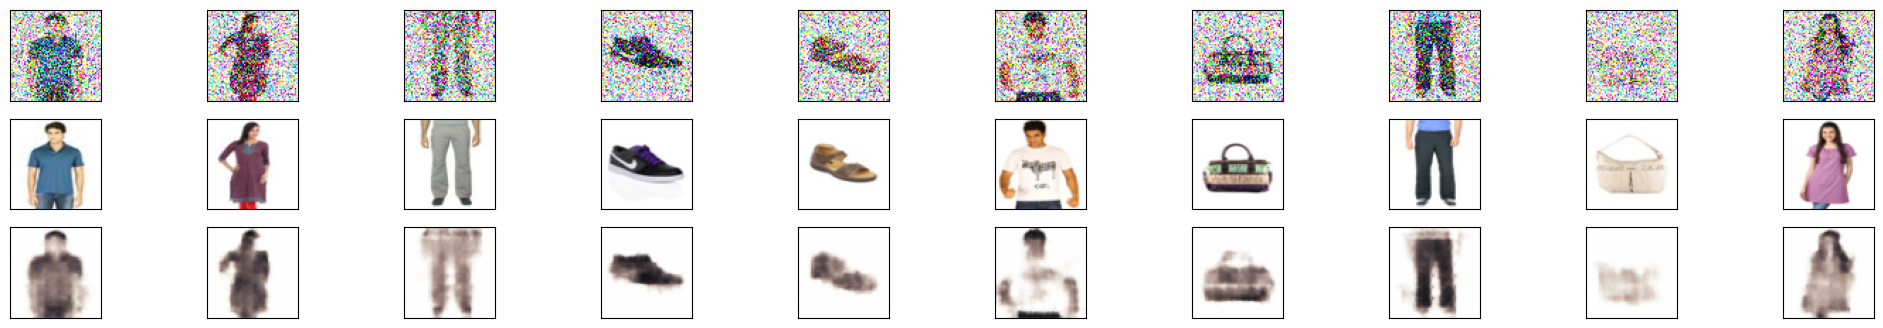

In [36]:
# 【初学者阅读说明】
# 这是 denoising_test.ipynb 的第 15 个单元格，属于历史学习实验。
# Notebook 与 .py 不同：多个单元格共享内核变量，通常要按顺序运行前置单元格。
# 本次只增加注释，保留原实验行为和已有输出；正式项目的修正请以各包内 .py 为准。

# 导入 matplotlib.pyplot，把图片张量绘制成可查看的对比图；as plt 给它起较短别名
import matplotlib.pyplot as plt  # 导入 matplotlib 库，用于绘图
# 这是 IPython 魔法命令，只能在 Notebook/IPython 中解释；inline 让图片显示在单元格下方。
%matplotlib inline
# 在 Jupyter Notebook 中内嵌显示图像

# 从验证数据加载器中获取一个批次的测试图像
# 创建验证集迭代器；迭代器记录已经取到哪里，next 才实际取下一批。
dataiter = iter(val_loader)  # 创建验证数据加载器的迭代器
# 取第一批验证数据，并按返回顺序解包为带噪输入和干净目标。
noisy_images, original_images = next(dataiter)  # 获取下一个批次的数据（图像和标签）

# 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
print("测试集 images 形状: ", noisy_images.shape)  # 打印图像的形状，通常是 (batch_size, channels, height, width)

# 实例化所需网络并移动到计算设备；此时参数仍需训练，或随后从权重文件加载。
model = model.to(device)  # 将模型移动到指定的设备

# 将输入或中间张量移动到模型所在的计算设备；数值含义不因移动设备而改变。
noisy_images = noisy_images.to(device)  # 将噪声图像移动到指定的设备
# 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
print("测试集 noisy_images 形状: ", noisy_images.shape)  # 打印图像的形状，通常是 (batch_size, channels, height, width)

# 获取模型的输出（去噪后的图像）
# 执行当前网络或当前层的前向运算，把结果保存为下一步要使用的张量。
output = model(noisy_images)  # 将噪声图像输入模型，得到去噪后的输出
# 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
print("测试集输出结果 output 形状: ", output.shape)  # 打印输出的形状，通常是 (batch_size, channels, height, width)

# 准备噪声图像用于显示
# 把图片或模型结果转换为适合显示的数组布局；PyTorch 常用通道在前，绘图库常用通道在后。
noisy_images = noisy_images.cpu().numpy()  # 将噪声图像从 PyTorch 张量转换为 NumPy 数组
# 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
print('noisy_imgs 转换为 numpy 数组后的形状: ', noisy_images.shape)  # 打印噪声图像的形状
# 把图片或模型结果转换为适合显示的数组布局；PyTorch 常用通道在前，绘图库常用通道在后。
noisy_images = np.moveaxis(noisy_images, 1, -1)  # 调整维度顺序，将通道维度移到最后一维，适配 matplotlib 的显示格式

# 将输出调整为批次图像的形状
# 执行当前网络或当前层的前向运算，把结果保存为下一步要使用的张量。
# 历史实验提醒：这里写死 batch_size 只适用于完整批；正式项目已取消这种强制重塑。
output = output.view(batch_size, 3, 64, 64)  # 将输出张量调整为 (batch_size, channels, height, width) 的形状
# 使用 detach() 分离梯度信息，并将其转换为 NumPy 数组
# 把图片或模型结果转换为适合显示的数组布局；PyTorch 常用通道在前，绘图库常用通道在后。
output = output.detach().cpu().numpy()  # 将输出从 PyTorch 张量转换为 NumPy 数组
# 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
print('output 转换为 numpy 数组后的形状: ', output.shape)  # 打印输出的形状
# 把图片或模型结果转换为适合显示的数组布局；PyTorch 常用通道在前，绘图库常用通道在后。
output = np.moveaxis(output, 1, -1)  # 调整维度顺序，将通道维度移到最后一维，适配 matplotlib 的显示格式
# 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
print('output 的通道维度移到最后一维后的形状: ', output.shape)  # 打印调整后的输出形状

# 把图片或模型结果转换为适合显示的数组布局；PyTorch 常用通道在前，绘图库常用通道在后。
original_images = original_images.cpu().numpy().transpose((0, 2, 3, 1))
# 打印当前进度、形状或结果，便于观察程序；print 本身不会训练或保存模型。
print("original_image shape: ", original_images.shape)

# 绘制前 10 张输入图像和重建图像
# 创建 3 行 10 列子图用于比较三组图片；sharex/sharey 共享坐标范围，figsize 用英寸指定画布大小。
fig, axes = plt.subplots(nrows=3, ncols=10, sharex=True, sharey=True, figsize=(25,4))  # 创建 2 行 10 列的子图
# 第一行显示噪声图像，第二行显示重建图像
# zip 将多个序列按位置配对；for 同时解包每一组，任一序列结束就停止。
for imgs, row in zip([noisy_images, original_images, output], axes):  # 遍历噪声图像和重建图像
    # zip 将多个序列按位置配对；for 同时解包每一组，任一序列结束就停止。
    for img, ax in zip(imgs, row):  # 遍历每张图像和对应的子图
        # 把 [H,W,C] 数组绘制在子图中；不要直接把 [C,H,W] 的 PyTorch 排列交给它。
        ax.imshow(np.squeeze(img))  # 显示图像，并去除多余的维度
        # 取出这个子图的 x 轴对象并隐藏它，只影响显示，不修改图像数据。
        ax.get_xaxis().set_visible(False)  # 隐藏 x 轴
        # 隐藏 y 轴对象，使注意力集中在图片本身。
        ax.get_yaxis().set_visible(False)  # 隐藏 y 轴
# 显示历史实验中的绘图结果；Notebook 内嵌输出或桌面窗口取决于绘图后端。
plt.show()  # 显示图像
